In [ ]:
import numpy as np
from numpy import linspace, zeros, exp, dot, eye
from numpy import linalg
from scipy.optimize import minimize
import matplotlib.pyplot as plt


In [ ]:
def system_matrix(s, N, h, x, M, l_y, l_z):
    A = zeros((M + 1, N + 1))
    G = -6.67e-11
    for i in range(M + 1):
        A[i, 0] = -0.5 * G * h / ((x[i] - s[0]) ** 2 + l_y ** 2 + l_z ** 2) ** 0.5
        for j in range(1, N):
            A[i, j] = -G * h / ((x[i] - s[j]) ** 2 + l_y ** 2 + l_z ** 2) ** 0.5
        A[i, N] = -0.5 * G * h / ((x[i] - s[N]) ** 2 + l_y ** 2 + l_z ** 2) ** 0.5
    return A


In [ ]:

def rho_model(s):
    return 2 * exp(-(s - 0.382) ** 2 / 0.009) + 1.2 * exp(-(s - 0.618) ** 2 / 0.018)



In [ ]:


if __name__ == "__main__":
    a, b = 0., 1.
    N_model = 100
    h_model = (b - a) / N_model
    s_model = linspace(a, b, N_model + 1)
    X_model = zeros(N_model + 1)
    for j in range(N_model + 1):
        X_model[j] = rho_model(s_model[j])


    c, d = -1., 2.
    M = 200
    x_grid = linspace(c, d, M + 1)
    l_y, l_z = 0.2, 0.1

    A_model = system_matrix(s_model, N_model, h_model, x_grid, M, l_y, l_z)
    B = dot(A_model, X_model)

    # 加噪声
    delta = 1e-11
    np.random.seed(1)
    B_delta = B + delta * B * (np.random.random(len(B)) - np.random.random(len(B)))
    delta_true = np.linalg.norm(B_delta - B)
    # 反演网格
    N = 50
    h = (b - a) / N
    s = linspace(a, b, N + 1)
    A = system_matrix(s, N, h, x_grid, M, l_y, l_z)




In [ ]:
def objective(c,N,B_delta,s,k,A):
    sum_s = np.zeros(N+1)

    for i in range(N+1):
        total = 0.0
        for j in range(k+1):
            total += c[j] * (s[i] ** j)
        sum_s[i] = total

    res = np.linalg.norm(A @ sum_s - B_delta) ** 2

    return res

In [ ]:

def rho_expended(c, x):
    rho = np.zeros_like(x)
    for i in range(len(x)):
        val = 0.0
        for j in range(len(c)):
            val += c[j] * x[i]**j
        rho[i] = val
    return rho


In [ ]:
#for k in range(20):
k=13
c0 = 10**-10 * np.ones(k+1)
result = minimize(objective, c0, args=(N,B_delta,s,k,A),method='L-BFGS-B',tol=1e-35)
c_ans = result.x

print(f"优化完成，是否收敛: {result.success}")
print(f'原因：{result.message} ')

X_exp = rho_expended(c_ans, s)
print(k)
#if np.linalg.norm(A @ X_exp - B_delta) **2< delta_true**2:
       #break




优化完成，是否收敛: True
原因：CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH 
13


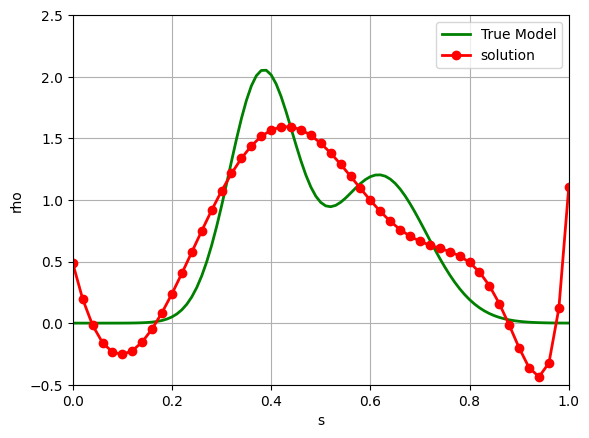

In [ ]:

fig = plt.figure()
ax = plt.axes(xlim=(a, b), ylim=(-0.5, 2.5))
ax.set_xlabel('s')
ax.set_ylabel('rho')
ax.plot(s_model, X_model, '-g', lw=2, label='True Model')
ax.plot(s, X_exp, '-or', lw=2, label='solution')
ax.legend()
plt.grid(True)
plt.show()